# Experiment Readout: ₹25 Cashback on the First Bill Payment (UPI app)
**Hypothesis:** a ₹25 cashback on the first in-app bill payment converts UPI-only users into bill payers, and the habit sticks.

**Design:** 200,000 eligible users (active on UPI, never paid a bill in-app), user-level 50/50 randomisation, 28 days (3–30 Nov 2025) plus a 28-day post-period with no cashback.

| Metric type | Metric |
|---|---|
| Primary | Bill-payment conversion within 28 days |
| Secondary | Bill payments per user, bill GMV per user, still paying bills in the post-period (habit) |
| Guardrails | Uninstalls, support tickets, refunds, P2P transfers (cannibalisation) |

> Synthetic data: `src/generate_data.py` (seed 41). Metrics built in SQL: `sql/user_metrics.sql`.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from experiment import *
import charts
df = user_metrics()
print(df.shape)
df.head(3)

(200000, 21)


,user_id,variant,city_tier,platform,age_band,tenure_group,pre_upi_txn_28d,pre_upi_gmv_28d,first_exposure_ts,app_version,...,converted,bill_payments,bill_gmv,cashback_paid,refunds,first_bill_ts,paid_bill_post_period,uninstalled_during_test,support_tickets,p2p_txn_during_test
0,U0000000,treatment,Tier 3,Android,35-44,Established,7,2020.0,2025-11-04 19:17:15,5.1.3,...,0,0,0.0,0.0,0.0,NaT,0,0,0,9
1,U0000001,control,Tier 2,Android,35-44,Established,1,600.0,2025-11-09 08:51:27,5.2.0,...,0,0,0.0,0.0,0.0,NaT,0,0,0,5
2,U0000002,control,Metro,Android,25-34,Established,6,1200.0,2025-11-24 12:10:58,5.1.3,...,0,0,0.0,0.0,0.0,NaT,0,0,0,2


## 0. Pre-registration: power
The historical 28-day conversion is about 5.5%. With 100K users per arm the test detects:

In [2]:
print(f"MDE at 80% power, alpha 0.05: {mde_for_power(0.055, 100_000):.2%} absolute")
print(f"Users per arm needed for a 0.5 pp MDE: {sample_size_per_arm(0.055, 0.005):,}")

MDE at 80% power, alpha 0.05: 0.29% absolute
Users per arm needed for a 0.5 pp MDE: 34,029


## 1. Validity checks
### 1a. Sample-ratio mismatch (SRM)

In [3]:
print('Assignment table:', srm_test(df.variant.value_counts().to_dict()))
e = df[df.exposure_logged == 1]
print('Exposure logs:   ', srm_test(e.variant.value_counts().to_dict()))

Assignment table: {'counts': {'treatment': 100118, 'control': 99882}, 'observed_split': {'treatment': 0.5006, 'control': 0.4994}, 'chi2': 0.28, 'p_value': 0.5976992134885006, 'srm_detected': False}
Exposure logs:    {'counts': {'control': 85829, 'treatment': 83404}, 'observed_split': {'control': 0.5072, 'treatment': 0.4928}, 'chi2': 34.75, 'p_value': 3.7513110433681356e-09, 'srm_detected': True}


Assignment is balanced, but the **exposure logs fail SRM**. Slicing by platform and app version localises the problem:

variant               control  treatment
platform app_version                    
Android  5.1.3          37095      37407
         5.2.0          37253      36833
iOS      5.1             4564       4624
         5.2             6917       4540

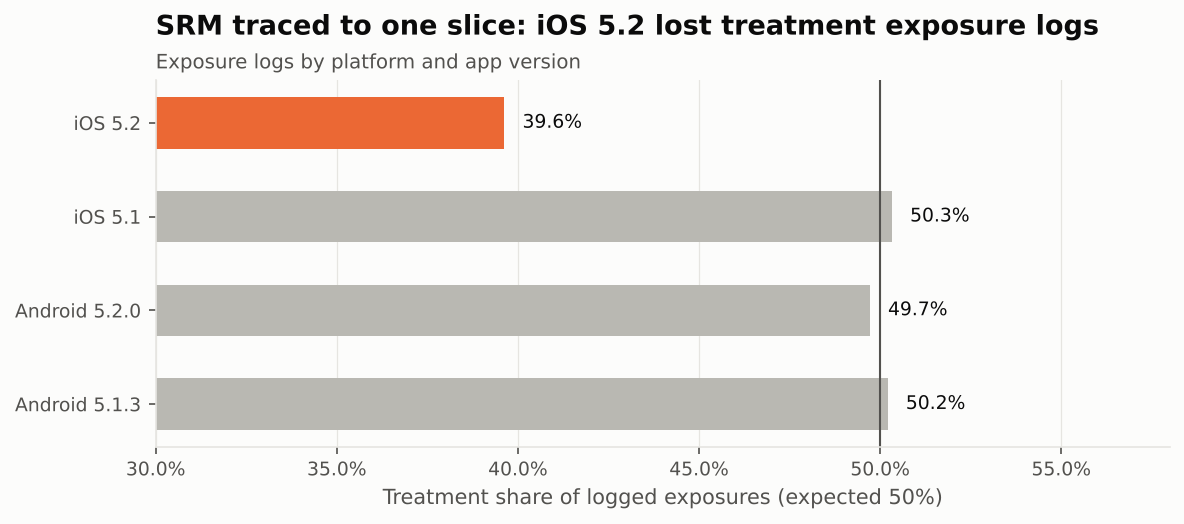

In [4]:
charts.srm_chart(e)
display(e.groupby(['platform', 'app_version', 'variant']).size().unstack())
display(Image('../images/srm_by_slice.png'))

In [5]:
clean = e[~((e.platform == 'iOS') & (e.app_version == '5.2'))]
srm_test(clean.variant.value_counts().to_dict())

{'counts': {'control': 78912, 'treatment': 78864},
 'observed_split': {'control': 0.5002, 'treatment': 0.4998},
 'chi2': 0.01,
 'p_value': 0.9038155518431772,
 'srm_detected': False}

**Diagnosis:** iOS v5.2 dropped treatment exposure events on 6–10 Nov (a client logging bug, not a randomisation bug). Excluding that slice restores the 50/50 ratio.

**Decision:** the **primary analysis is intention-to-treat on the assignment table**, which does not depend on exposure logging. Exposure-based (triggered) numbers are reported only with iOS 5.2 excluded from both arms.

### 1b. Covariate balance (pre-period)

In [6]:
bal = balance_table(df, ['city_tier', 'platform', 'age_band', 'tenure_group', 'pre_upi_txn_28d', 'pre_upi_gmv_28d'])
print('All |SMD| < 0.1:', bal.balanced.all())
bal

All |SMD| < 0.1: True


,covariate,treatment,control,smd,balanced
0,city_tier_Metro,0.3414,0.3390,0.0051,True
1,city_tier_Tier 1,0.2633,0.2630,0.0006,True
2,city_tier_Tier 2,0.2387,0.2393,-0.0013,True
3,city_tier_Tier 3,0.1567,0.1588,-0.0058,True
4,platform_Android,0.8650,0.8664,-0.0040,True
5,platform_iOS,0.1350,0.1336,0.0040,True
6,age_band_18-24,0.2796,0.2813,-0.0038,True
7,age_band_25-34,0.3774,0.3768,0.0013,True
8,age_band_35-44,0.2221,0.2214,0.0017,True
9,age_band_45+,0.1209,0.1205,0.0012,True


## 2. Primary metric: conversion

In [7]:
t, c = df[df.variant == 'treatment'], df[df.variant == 'control']
primary = proportion_test(int(t.converted.sum()), len(t), int(c.converted.sum()), len(c))
pd.Series(primary).round(5)

control       0.05551
treatment     0.07057
abs_lift      0.01506
rel_lift      0.27135
ci_low        0.01293
ci_high       0.01719
z            13.85672
p_value       0.00000
dtype: float64

## 3. Secondary metrics
Bill GMV is heavy-tailed and mostly zero, so a bootstrap CI is reported next to Welch's t-test.

In [8]:
rows = {}
for m in ['bill_payments', 'bill_gmv', 'paid_bill_post_period']:
    r = welch_test(t[m].to_numpy(float), c[m].to_numpy(float))
    if m == 'bill_gmv':
        r['boot_ci_low'], r['boot_ci_high'] = bootstrap_diff_ci(t[m].to_numpy(float), c[m].to_numpy(float))
    rows[m] = r
pd.DataFrame(rows).T.round(4)

,control,treatment,abs_lift,rel_lift,ci_low,ci_high,se,p_value,boot_ci_low,boot_ci_high
bill_payments,0.0763,0.0960,0.0197,0.2586,0.0165,0.0229,0.0016,0.0,NaN,NaN
bill_gmv,92.1882,113.9726,21.7844,0.2363,17.0194,26.5495,2.4312,0.0,16.7017,26.7189
paid_bill_post_period,0.0359,0.0420,0.0061,0.1713,0.0045,0.0078,0.0009,0.0,NaN,NaN


## 4. CUPED variance reduction
Adjust each metric with its pre-period counterpart. CUPED helps a lot when the covariate predicts the metric (P2P transfers), and barely helps for a sparse first-time-behaviour metric (conversion), which is itself a useful finding.

,variance_reduction,lift_raw,p_raw,lift_cuped,p_cuped,ci_width_raw,ci_width_cuped
p2p_txn_during_test,0.7769,0.0312,0.4149,0.0141,0.4342,1.0,0.4724
bill_gmv,0.0018,21.7844,0.0000,21.6159,0.0000,1.0,0.9991
converted,0.0006,0.0151,0.0000,0.0150,0.0000,1.0,0.9997


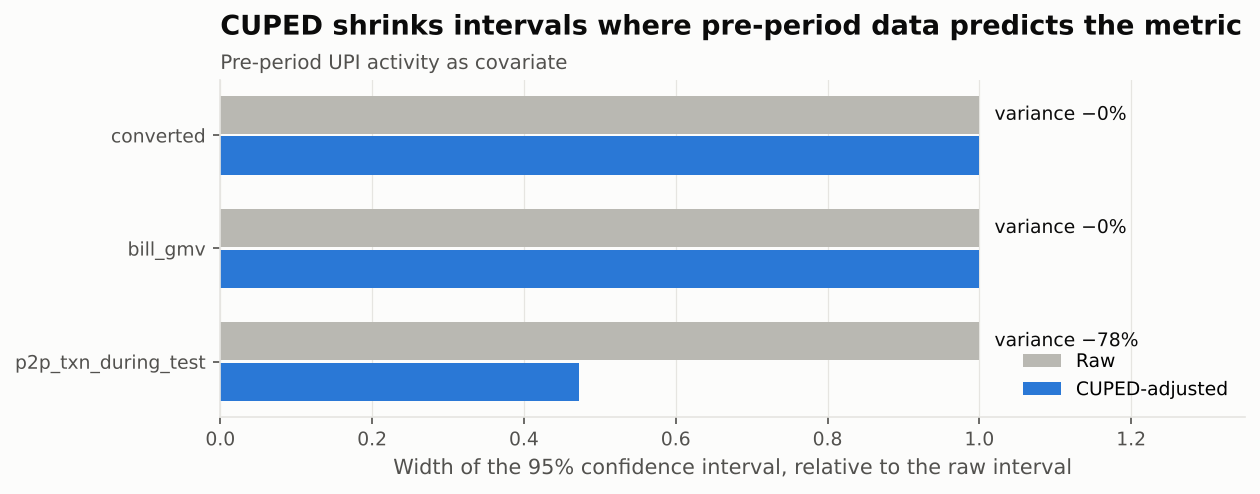

In [9]:
res = {}
for metric, cov in [('p2p_txn_during_test', 'pre_upi_txn_28d'), ('bill_gmv', 'pre_upi_gmv_28d'), ('converted', 'pre_upi_txn_28d')]:
    raw = welch_test(t[metric].to_numpy(float), c[metric].to_numpy(float))
    adj, vr = cuped(df, metric, cov)
    a = welch_test(adj[t.index].to_numpy(), adj[c.index].to_numpy())
    res[metric] = {'variance_reduction': vr, 'lift_raw': raw['abs_lift'], 'p_raw': raw['p_value'], 'lift_cuped': a['abs_lift'],
                   'p_cuped': a['p_value'], 'ci_width_raw': 1.0, 'ci_width_cuped': a['se'] / raw['se']}
cup = pd.DataFrame(res).T
charts.cuped_chart(cup)
display(cup.round(4))
display(Image('../images/cuped.png'))

## 5. Who does it work for? Segments with Holm correction
Multiple segments mean multiple tests, so p-values are Holm-adjusted across every segment shown.

,users,control,treatment,abs_lift,rel_lift,ci_low,ci_high,p_value,p_holm
segment,,,,,,,,,
Metro,68036,0.0630,0.0664,0.0034,0.0532,-0.0003,0.0070,0.0756,0.0756
Tier 1,52628,0.0533,0.0670,0.0137,0.2570,0.0096,0.0178,0.0000,0.0000
Tier 2,47793,0.0506,0.0758,0.0252,0.4976,0.0208,0.0296,0.0000,0.0000
Tier 3,31543,0.0504,0.0776,0.0272,0.5401,0.0218,0.0326,0.0000,0.0000
Established,137044,0.0555,0.0685,0.0130,0.2334,0.0104,0.0155,0.0000,0.0000
New (<6 months),62956,0.0554,0.0750,0.0196,0.3539,0.0158,0.0235,0.0000,0.0000
Android,173140,0.0553,0.0713,0.0160,0.2901,0.0137,0.0183,0.0000,0.0000
iOS,26860,0.0569,0.0656,0.0088,0.1541,0.0030,0.0145,0.0027,0.0055


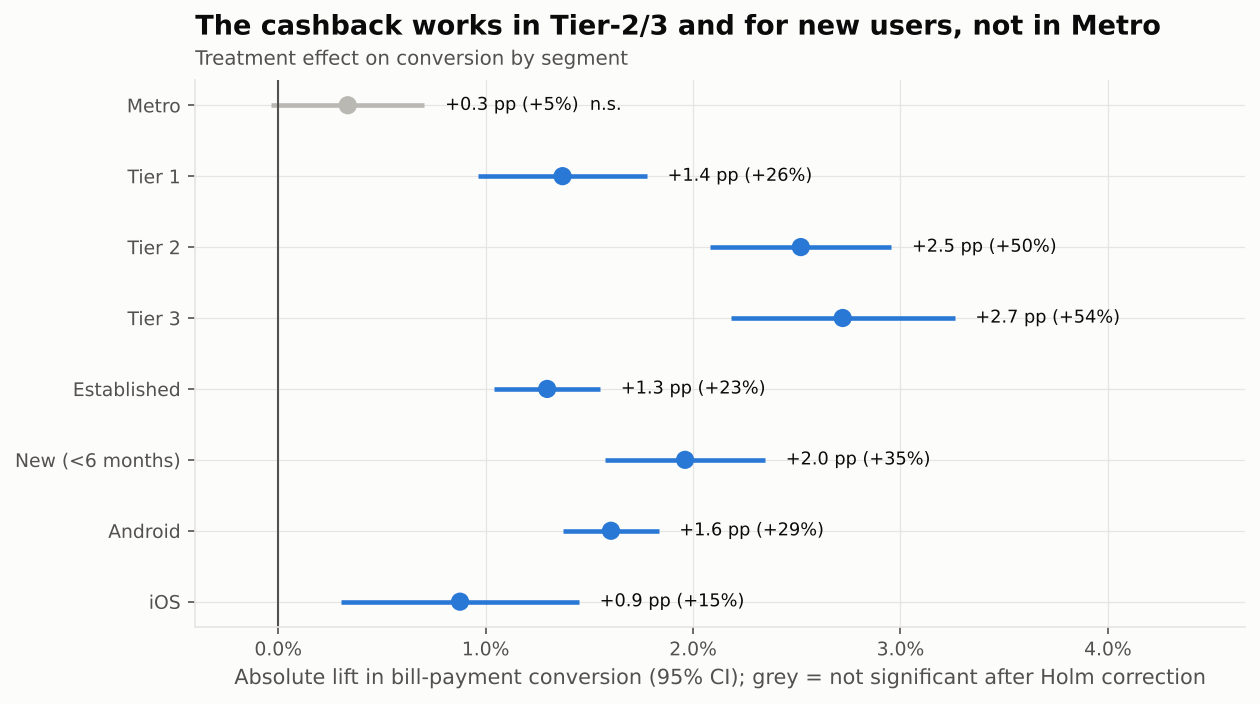

In [10]:
seg = pd.concat([segment_effects(df, 'city_tier'), segment_effects(df, 'tenure_group'), segment_effects(df, 'platform')])
seg['p_holm'] = holm(seg.p_value)
charts.segment_forest(seg)
display(seg.round(4))
display(Image('../images/segment_lift.png'))

## 6. Novelty: is the effect front-loaded?

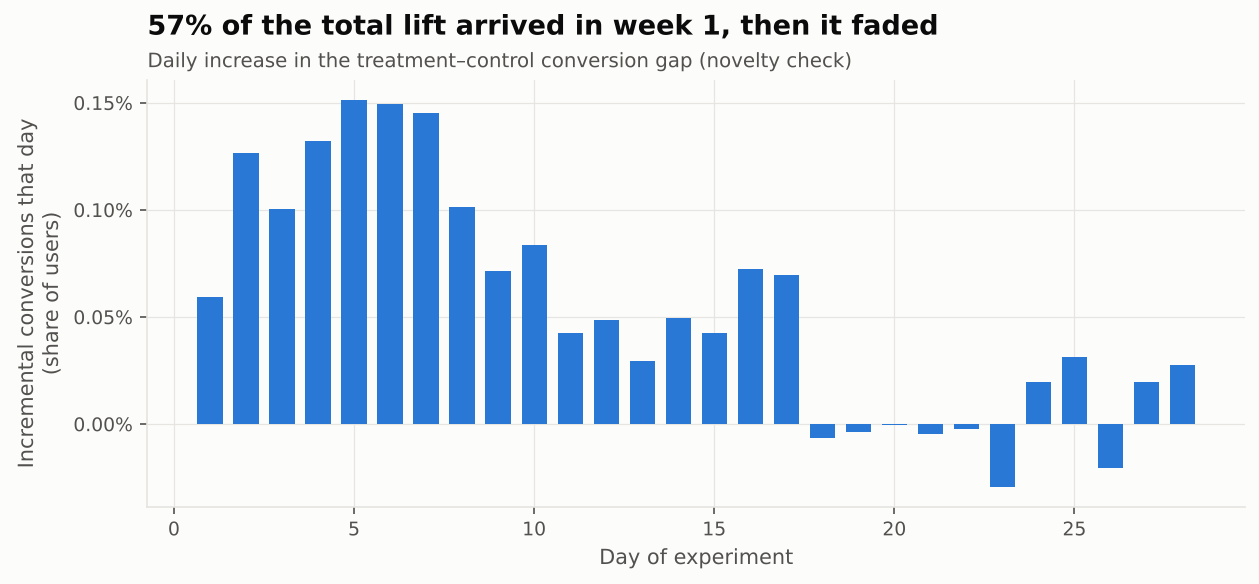

In [11]:
daily = daily_effect(df, pd.Timestamp('2025-11-03'))
charts.novelty_chart(daily)
display(Image('../images/novelty.png'))

## 7. Guardrails

In [12]:
g = {m: welch_test(t[m].to_numpy(float), c[m].to_numpy(float)) for m in ['uninstalled_during_test', 'support_tickets', 'refunds', 'p2p_txn_during_test']}
pd.DataFrame(g).T[['control', 'treatment', 'rel_lift', 'p_value']].round(4)

,control,treatment,rel_lift,p_value
uninstalled_during_test,0.0208,0.0210,0.0106,0.7300
support_tickets,0.0275,0.0296,0.0754,0.0060
refunds,0.0010,0.0015,0.4915,0.0018
p2p_txn_during_test,8.5141,8.5453,0.0037,0.4149


## 8. Does it pay? ROI by rollout scenario
Cost = ₹25 to *every* first-time treatment payer, including those who would have paid anyway (subsidy leakage). Benefit = biller commission on incremental bills (₹4 each, an assumption) plus the 12-month value of incremental users still paying bills after the cashback ends (₹180 each, an assumption).

,cashback_cost_per_1k,payers_per_1k_treatment,incremental_payers_per_1k,subsidy_leakage_pct,cost_per_incremental_payer,incremental_retained_payers_per_1k,benefit_per_1k,net_per_1k,roi
All users,1764.17,70.57,15.06,78.66,117.13,6.15,1185.56,-578.61,-0.33
Metro,1659.60,66.38,3.35,94.95,495.08,0.41,87.76,-1571.84,-0.95
Tier 1,1675.96,67.04,13.71,79.55,122.26,5.61,1075.17,-600.79,-0.36
Tier 2,1895.71,75.83,25.19,66.77,75.24,11.26,2169.82,274.11,0.14
Tier 3,1939.88,77.60,27.21,64.93,71.28,11.66,2242.04,302.17,0.16
Tier 2 + 3 (recommended),1913.21,76.53,26.00,66.03,73.60,11.41,2197.65,284.44,0.15


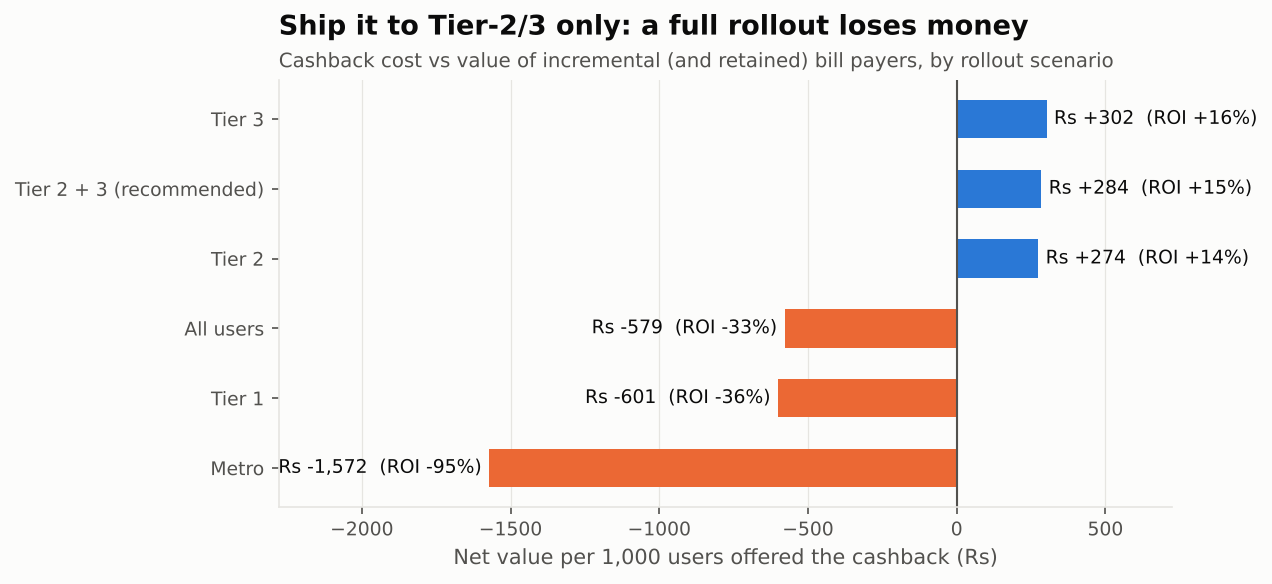

In [13]:
scen = {'All users': df, 'Metro': df[df.city_tier == 'Metro'], 'Tier 1': df[df.city_tier == 'Tier 1'],
        'Tier 2': df[df.city_tier == 'Tier 2'], 'Tier 3': df[df.city_tier == 'Tier 3'],
        'Tier 2 + 3 (recommended)': df[df.city_tier.isin(['Tier 2', 'Tier 3'])]}
roi_tbl = pd.DataFrame({k: roi(v) for k, v in scen.items()}).T
charts.roi_chart(roi_tbl)
roi_tbl.to_csv('../reports/rollout_roi.csv')
display(roi_tbl)
display(Image('../images/rollout_roi.png'))

In [14]:
# sensitivity: how valuable must a retained bill payer be for a FULL rollout to break even?
pd.Series({v: roi(df, value_per_retained_payer=v)['roi'] for v in (180, 240, 300, 360)}, name='roi_all_users')

180   -0.33
240   -0.12
300    0.09
360    0.30
Name: roi_all_users, dtype: float64

## Decision
**Do not ship to everyone. Ship to Tier-2/3 users**, and re-test Metro with a smaller incentive. Fix iOS 5.2 exposure logging before the next test, and watch the support-ticket guardrail. See the README for the summary.